# EN3160 Assignment 2
## Fitting and Alignment

**Name:** Kumarasinghe M. N.  
**Index:** 230355X

In [19]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

## Question 1

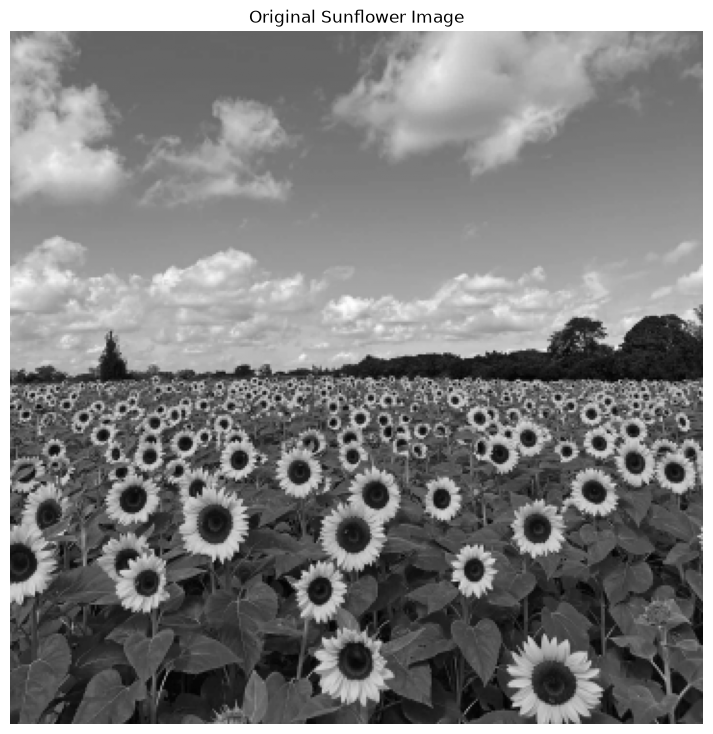

Image dimensions: (360, 360)


In [ ]:

from scipy.ndimage import maximum_filter

# Read the sunflower image at a reduced resolution
image = cv.imread(
    'a2images/the_berry_farms_sunflower_field.jpeg',
    cv.IMREAD_REDUCED_COLOR_4
)

assert image is not None, "Could not load the sunflower image."

# Convert the image to grayscale and normalize pixel values
gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

# Display the input image
plt.figure(figsize=(9, 9))
plt.imshow(gray_image, cmap='gray')
plt.title('Original Sunflower Image')
plt.axis('off')
plt.show()

print("Image dimensions:", gray_image.shape)

In [52]:


# Define the scales to examine
scales = np.linspace(1, 10, 10)

# Set the threshold for accepting blob responses
response_threshold = 0.15

height, width = gray_image.shape

# Store the LoG responses at all scales
scale_space = []

for sigma in scales:

    print(f"Processing sigma = {sigma:.2f}")

    # Construct the LoG kernel
    half_size = round(3 * sigma)

    xx, yy = np.meshgrid(
        np.arange(-half_size, half_size + 1),
        np.arange(-half_size, half_size + 1)
    )

    distance_squared = xx**2 + yy**2

    log_kernel = (
        (distance_squared / (2 * sigma**2) - 1)
        * np.exp(-distance_squared / (2 * sigma**2))
        / (np.pi * sigma**4)
    )

    # Apply scale normalization
    log_kernel = sigma**2 * log_kernel

    # Calculate the squared LoG response
    response = cv.filter2D(
        gray_image, cv.CV_32F, log_kernel
    )
    response = response**2

    # Store the response for this scale
    scale_space.append(response)

# Convert the list into a 3D array:
# (number of scales, image height, image width)
scale_space = np.stack(scale_space, axis=0)

print("Scale-space dimensions:", scale_space.shape)

Processing sigma = 1.00
Processing sigma = 2.00
Processing sigma = 3.00
Processing sigma = 4.00
Processing sigma = 5.00
Processing sigma = 6.00
Processing sigma = 7.00
Processing sigma = 8.00
Processing sigma = 9.00
Processing sigma = 10.00
Scale-space dimensions: (10, 360, 360)


In [53]:
# Find local maxima across space AND scale
neighbourhood_max = maximum_filter(
    scale_space,
    size=(3, 3, 3)
)

# Apply the response threshold
threshold_value = (
    response_threshold * scale_space.max()
)

# Identify scale-space extrema
extrema_mask = (
    (scale_space == neighbourhood_max)
    & (scale_space >= threshold_value)
)

# Exclude the first and last scales because they
# do not have neighbours on both sides in scale
extrema_mask[0, :, :] = False
extrema_mask[-1, :, :] = False

# Extract the detected extrema
scale_indices, rows, cols = np.where(extrema_mask)

# Store each detection as (x, y, sigma, response)
detected_blobs = []

for scale_idx, row, col in zip(
    scale_indices, rows, cols
):
    sigma = scales[scale_idx]
    strength = scale_space[scale_idx, row, col]

    detected_blobs.append(
        (col, row, sigma, strength)
    )

print("Total scale-space extrema:", len(detected_blobs))

Total scale-space extrema: 400


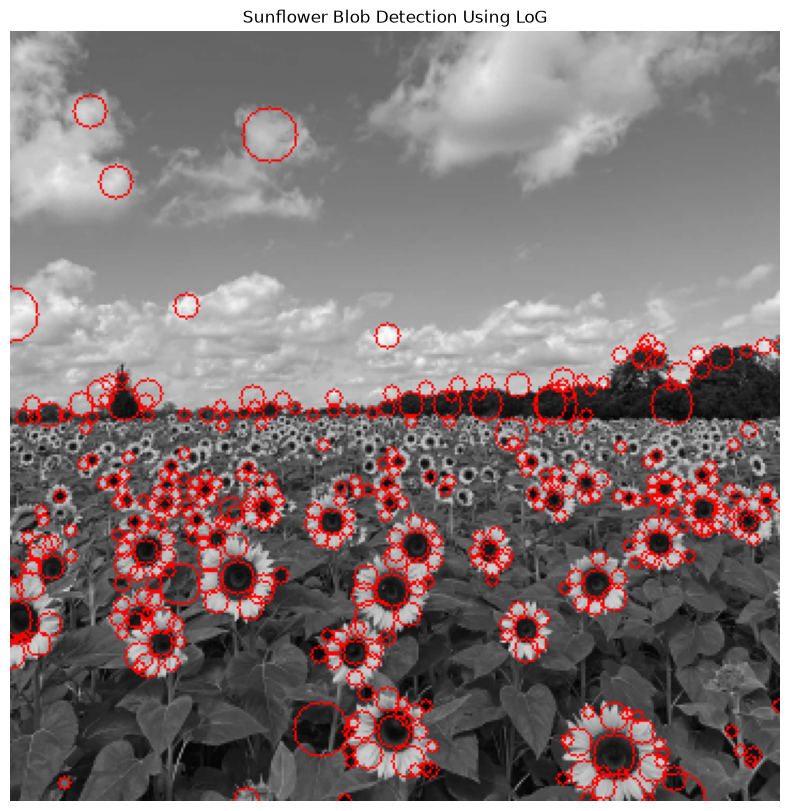

Largest detected blob:
Centre: (121, 48)
Sigma: 9.00
Radius: 12.73 pixels
Diameter: 25.46 pixels
Response strength: 0.02699


In [54]:
# Sort detections by radius, from largest to smallest
detected_blobs.sort(
    key=lambda blob: 2 * blob[2],
    reverse=True
)

# Prepare the image for drawing circles
result_image = cv.cvtColor(
    (gray_image * 255).astype(np.uint8),
    cv.COLOR_GRAY2BGR
)

# Draw all detected circles
for x, y, sigma, strength in detected_blobs:
    radius = int(round(np.sqrt(2) * sigma))

    cv.circle(
        result_image,
        (int(x), int(y)),
        radius,
        (0, 0, 255),
        1
    )

# Display the detection result
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(result_image, cv.COLOR_BGR2RGB))
plt.title('Sunflower Blob Detection Using LoG')
plt.axis('off')
plt.show()

# Report the largest detection based on radius
if detected_blobs:
    x, y, sigma, strength = detected_blobs[0]

    radius = np.sqrt(2) * sigma

    print("Largest detected blob:")
    print(f"Centre: ({x}, {y})")
    print(f"Sigma: {sigma:.2f}")
    print(f"Radius: {radius:.2f} pixels")
    print(f"Diameter: {2 * radius:.2f} pixels")
    print(f"Response strength: {strength:.5f}")
else:
    print("No blobs were detected.")

### Question 1: Blob Detection Using Laplacian of Gaussians

The sunflower image was processed using a scale-normalized Laplacian of Gaussian (LoG) filter. Scale-space extrema were detected by comparing responses across spatial dimensions and neighbouring scales. A threshold of 15% of the maximum squared LoG response was applied.

**Scale values used:**

$$
\sigma \in \{1,2,3,4,5,6,7,8,9,10\}
$$

**Largest detected blob:**

- **Centre:** $(121,48)$ pixels
- **Scale:** $\sigma = 9$
- **Radius:** $r = \sqrt{2}\sigma \approx 12.73$ pixels
- **Diameter:** $d = 2r \approx 25.46$ pixels

The radius was calculated using $r = \sqrt{2}\sigma$. The detected circles were drawn on the image to visualize the blob detection results.

## Question 2

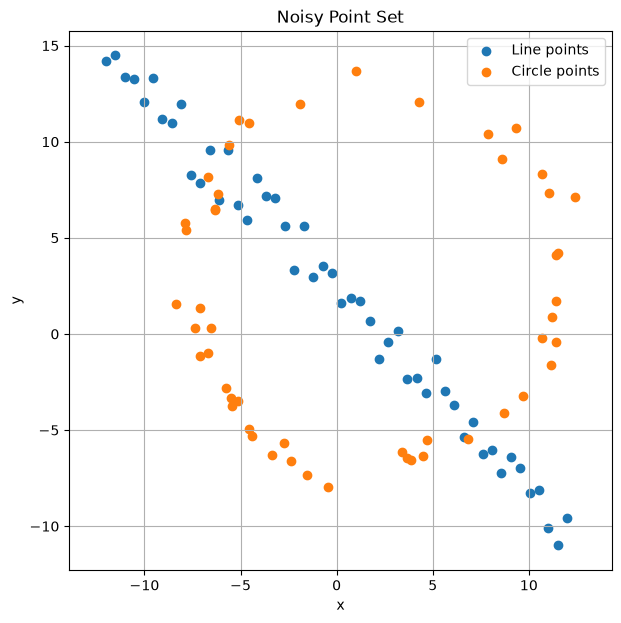

In [13]:

from scipy.optimize import minimize

np.random.seed(0)

# Generate points belonging to a circle and a line
N = 100
n_points = N // 2

# Circle parameters
radius_true = 10
center_x, center_y = 2, 3

angles = np.random.uniform(0, 2 * np.pi, n_points)
noise_circle = (radius_true / 16) * np.random.randn(n_points)

circle_x = center_x + (radius_true + noise_circle) * np.cos(angles)
circle_y = center_y + (radius_true + noise_circle) * np.sin(angles)

circle_points = np.column_stack((circle_x, circle_y))

# Line parameters
slope_true, intercept_true = -1, 2

line_x = np.linspace(-12, 12, n_points)
line_y = slope_true * line_x + intercept_true + np.random.randn(n_points)

line_points = np.column_stack((line_x, line_y))

# Combine both sets of points
points = np.vstack((circle_points, line_points))

# Display the generated data
plt.figure(figsize=(7, 7))
plt.scatter(line_points[:, 0], line_points[:, 1], label="Line points")
plt.scatter(circle_points[:, 0], circle_points[:, 1], label="Circle points")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Noisy Point Set")
plt.axis("equal")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:


# Calculate perpendicular distances from points to a line
def distance_to_line(model, data):
    a, b, d = model
    return np.abs(a * data[:, 0] + b * data[:, 1] + d)


# Estimate a line using RANSAC
def fit_line_ransac(data, iterations=1000, tolerance=0.6, min_consensus=35):
    best_model = None
    best_inliers = np.array([], dtype=int)
    best_sample_indices = None

    for _ in range(iterations):
        sample = np.random.choice(len(data), 2, replace=False)
        p1, p2 = data[sample]

        a = p2[1] - p1[1]
        b = p1[0] - p2[0]
        d = -(a * p1[0] + b * p1[1])

        norm = np.sqrt(a**2 + b**2)
        if norm == 0:
            continue

        model = np.array([a, b, d]) / norm

        distances = distance_to_line(model, data)
        inlier_indices = np.where(distances < tolerance)[0]

        if (len(inlier_indices) > len(best_inliers)
                and len(inlier_indices) >= min_consensus):
            best_model = model
            best_inliers = inlier_indices
            best_sample_indices = sample.copy()

    return best_model, best_inliers, best_sample_indices


# Calculate radial distances from points to a circle
def distance_to_circle(model, data):
    cx, cy, radius = model
    distances = np.sqrt(
        (data[:, 0] - cx)**2 + (data[:, 1] - cy)**2
    )
    return np.abs(distances - radius)


# Estimate a circle using RANSAC
def fit_circle_ransac(data, iterations=1000, tolerance=1.5, min_consensus=45):
    best_model = None
    best_inliers = np.array([], dtype=int)
    best_sample_indices = None

    for _ in range(iterations):
        sample_indices = np.random.choice(len(data), 3, replace=False)
        p1, p2, p3 = data[sample_indices]

        matrix = np.array([
            [p1[0], p1[1], 1],
            [p2[0], p2[1], 1],
            [p3[0], p3[1], 1]
        ])

        values = -np.array([
            p1[0]**2 + p1[1]**2,
            p2[0]**2 + p2[1]**2,
            p3[0]**2 + p3[1]**2
        ])

        try:
            solution = np.linalg.solve(matrix, values)
        except np.linalg.LinAlgError:
            continue

        cx = -solution[0] / 2
        cy = -solution[1] / 2
        radius_squared = cx**2 + cy**2 - solution[2]

        if radius_squared <= 0:
            continue

        radius = np.sqrt(radius_squared)
        model = np.array([cx, cy, radius])

        distances = distance_to_circle(model, data)
        inlier_indices = np.where(distances < tolerance)[0]

        if (len(inlier_indices) > len(best_inliers)
                and len(inlier_indices) >= min_consensus):
            best_model = model
            best_inliers = inlier_indices
            best_sample_indices = sample_indices.copy()

    return best_model, best_inliers, best_sample_indices


# Refine a circle by minimizing squared radial errors
def refine_circle(inlier_points, initial_model):
    def objective(model):
        errors = distance_to_circle(model, inlier_points)
        return np.sum(errors**2)

    result = minimize(
        objective,
        initial_model,
        method="Nelder-Mead"
    )

    if not result.success:
        print("Warning: Circle refinement did not fully converge.")

    return result.x


# Fit the line first
line_model, line_inlier_indices, line_sample_indices = (
    fit_line_ransac(points)
)

if line_model is None:
    raise RuntimeError("RANSAC could not find a suitable line.")

# Remove line inliers before fitting the circle
remaining_indices = np.setdiff1d(
    np.arange(len(points)), line_inlier_indices
)
remaining_points = points[remaining_indices]

circle_model, circle_inlier_indices, circle_sample_indices = (
    fit_circle_ransac(remaining_points)
)

if circle_model is None:
    raise RuntimeError("RANSAC could not find a suitable circle.")

# Convert circle indices to the original point set
circle_inlier_indices = remaining_indices[circle_inlier_indices]
circle_sample_indices = remaining_indices[circle_sample_indices]

# Preserve the original RANSAC circle
ransac_circle_model = circle_model.copy()

# Refine the circle using all its inliers
circle_model = refine_circle(
    points[circle_inlier_indices],
    ransac_circle_model
)

print("Line model [a, b, d]:", line_model)
print("Number of line inliers:", len(line_inlier_indices))
print("Number of line sample points:", len(line_sample_indices))

print("\nOriginal RANSAC circle [cx, cy, radius]:",
      ransac_circle_model)
print("Refined circle [cx, cy, radius]:", circle_model)
print("Number of circle inliers:", len(circle_inlier_indices))
print("Number of circle sample points:", len(circle_sample_indices))

Line model [a, b, d]: [-0.7184192  -0.69561041  1.47534491]
Number of line inliers: 36
Number of line sample points: 2

Original RANSAC circle [cx, cy, radius]: [ 1.82778778  3.25605332 10.03379598]
Refined circle [cx, cy, radius]: [1.94667077 3.00051106 9.89734016]
Number of circle inliers: 52
Number of circle sample points: 3


Number of line sample points: 2
Number of circle sample points: 3


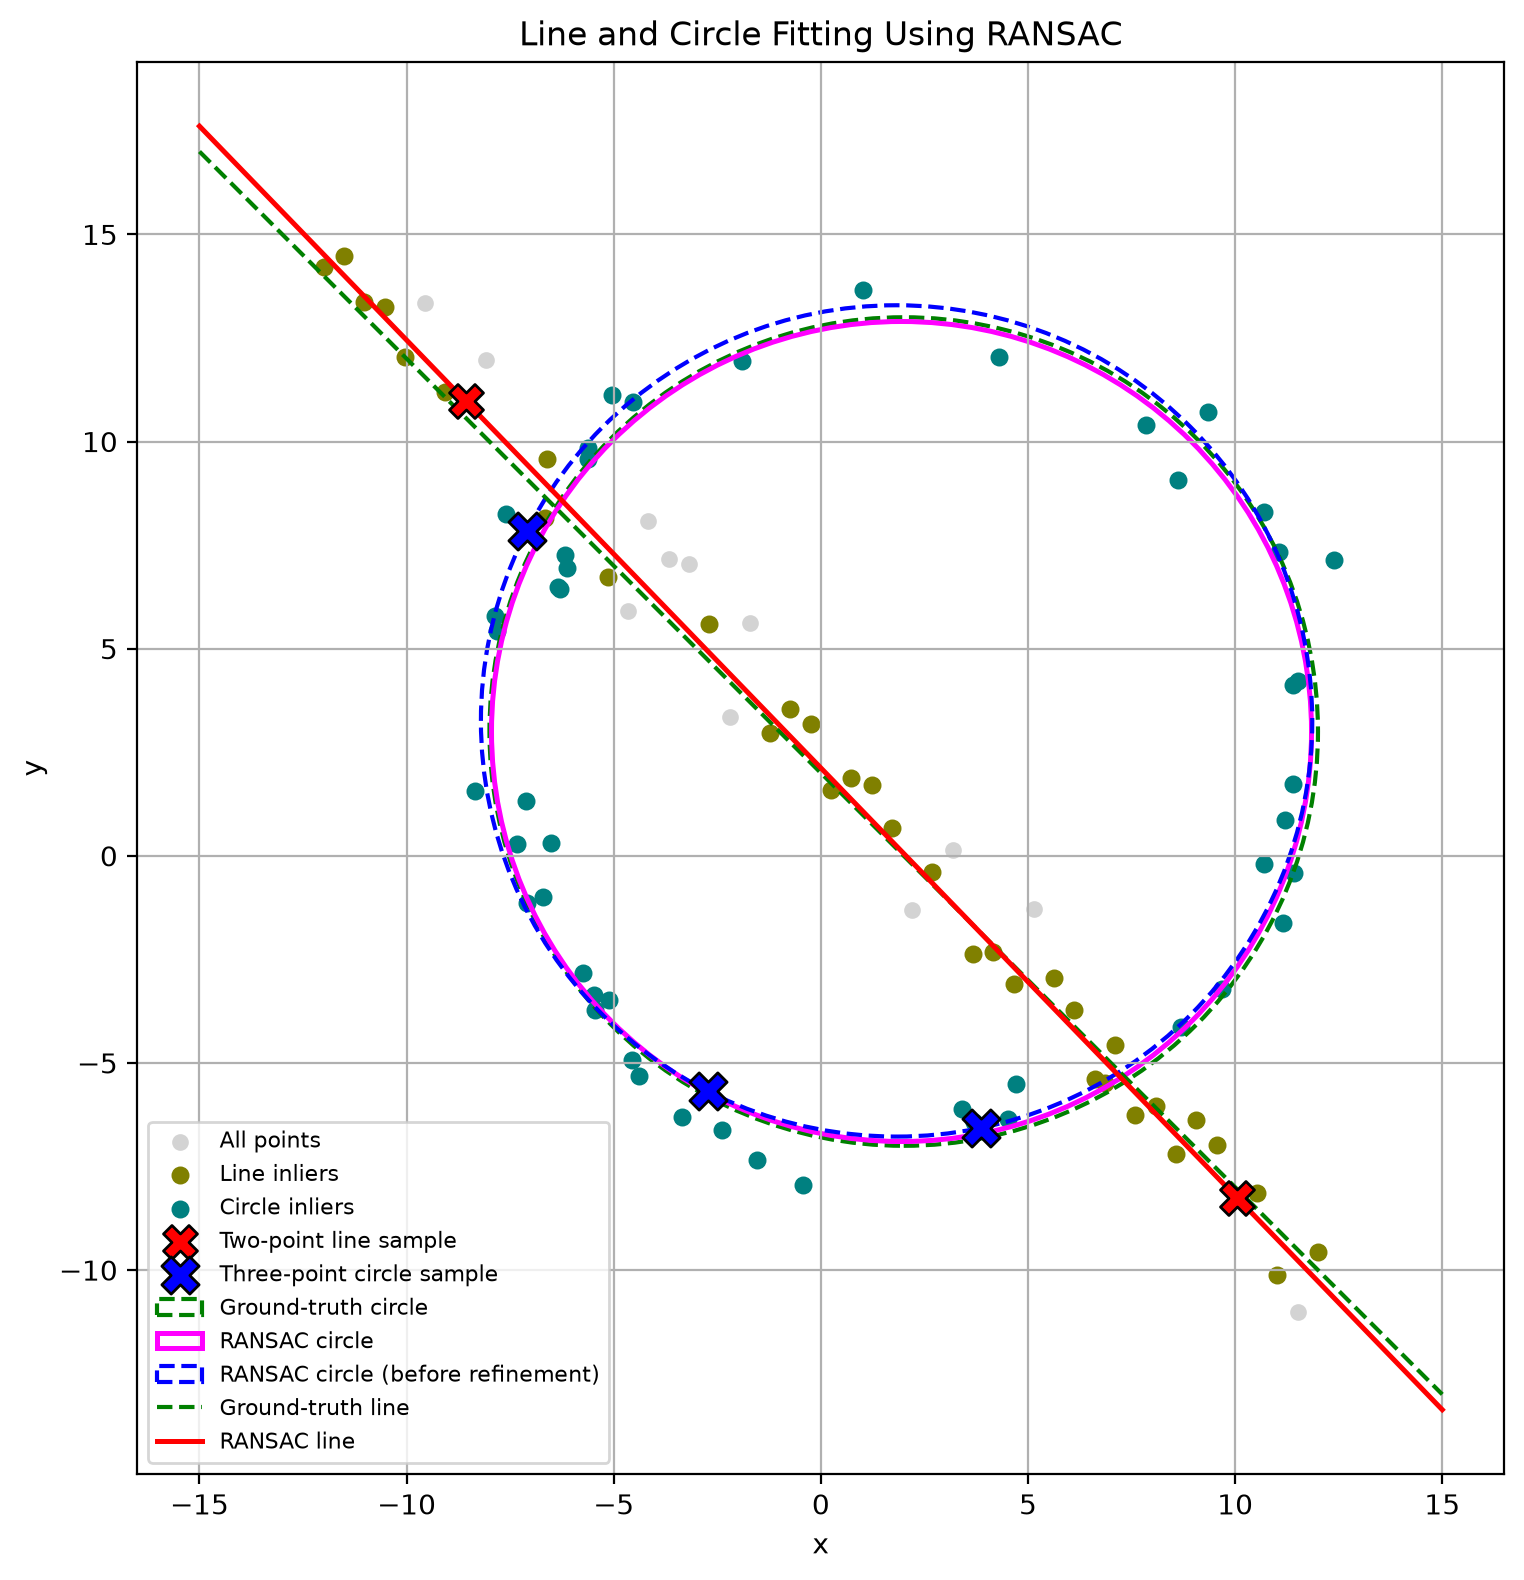

In [17]:
fig, ax = plt.subplots(figsize=(8, 8), dpi=200)

# Verify the number of sampled points
print("Number of line sample points:", len(line_sample_indices))
print("Number of circle sample points:", len(circle_sample_indices))

# Plot all points
ax.scatter(
    points[:, 0], points[:, 1],
    s=25,
    color="lightgray",
    label="All points"
)

# Plot line inliers
ax.scatter(
    points[line_inlier_indices, 0],
    points[line_inlier_indices, 1],
    s=30,
    color="olive",
    marker="o",
    label="Line inliers"
)

# Plot circle inliers
ax.scatter(
    points[circle_inlier_indices, 0],
    points[circle_inlier_indices, 1],
    s=30,
    color="teal",
    marker="o",
    label="Circle inliers"
)

# Highlight the actual two points used for the best line model
ax.scatter(
    points[line_sample_indices, 0],
    points[line_sample_indices, 1],
    color="red",
    marker="X",
    s=150,
    edgecolors="black",
    linewidths=1,
    label="Two-point line sample",
    zorder=10
)

# Highlight the actual three points used for the best circle model
ax.scatter(
    points[circle_sample_indices, 0],
    points[circle_sample_indices, 1],
    color="blue",
    marker="X",
    s=180,
    edgecolors="black",
    linewidths=1,
    label="Three-point circle sample",
    zorder=11
)

# Plot the ground-truth circle
true_circle = plt.Circle(
    (center_x, center_y),
    radius_true,
    fill=False,
    color="green",
    linestyle="--",
    linewidth=1.5,
    label="Ground-truth circle"
)
ax.add_patch(true_circle)

# Plot the estimated circle
cx, cy, estimated_radius = circle_model

fitted_circle = plt.Circle(
    (cx, cy),
    estimated_radius,
    fill=False,
    color="magenta",
    linewidth=1.8,
    label="RANSAC circle"
)
ax.add_patch(fitted_circle)

# Plot the circle estimated directly by RANSAC
rcx, rcy, rradius = ransac_circle_model

initial_circle = plt.Circle(
    (rcx, rcy),
    rradius,
    fill=False,
    color="blue",
    linestyle="--",
    linewidth=1.5,
    label="RANSAC circle (before refinement)"
)
ax.add_patch(initial_circle)

# Plot the ground-truth line
x_range = np.array([-15, 15])

ax.plot(
    x_range,
    slope_true * x_range + intercept_true,
    color="green",
    linestyle="--",
    linewidth=1.5,
    label="Ground-truth line"
)

# Plot the estimated line
a, b, d = line_model

if abs(b) > 1e-8:
    ax.plot(
        x_range,
        -(a * x_range + d) / b,
        color="red",
        linewidth=1.8,
        label="RANSAC line"
    )
else:
    x_line = -d / a
    ax.axvline(
        x_line,
        color="red",
        linewidth=1.8,
        label="RANSAC line"
    )

# Configure the plot
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Line and Circle Fitting Using RANSAC")
ax.set_aspect("equal", adjustable="box")
ax.legend(fontsize=8)
ax.grid(True)

plt.tight_layout()
plt.show()

### (a) Line Estimation Using RANSAC

The line is represented by the parameters $(a,b,d)$ and satisfies

$$
ax+by+d=0,\qquad a^2+b^2=1.
$$

RANSAC was implemented using 1000 iterations, a normal-distance threshold of $0.6$, and a minimum consensus of 35 points. Two points were randomly sampled to generate each line hypothesis.

The estimated line parameters were

$$
(a,b,d)=(-0.71841920,-0.69561041,1.47534491).
$$

The algorithm identified **36 line inliers**, using a sample of **2 points** to generate the selected line hypothesis. The estimated line is close to the ground-truth line $y=-x+2$.

### (b) Circle Estimation Using RANSAC

After removing the line inliers, RANSAC was applied to the remaining points to estimate the circle. The radial error was calculated as

$$
e_i=\left|\sqrt{(x_i-c_x)^2+(y_i-c_y)^2}-r\right|.
$$

Circle fitting used 1000 iterations, a radial-error threshold of $1.5$, and a minimum consensus of 45 points. Three points were randomly sampled to generate each circle hypothesis.

The initial RANSAC circle estimate was

$$
(c_x,c_y,r)=(1.82778778,3.25605332,10.03379598).
$$

RANSAC identified **52 circle inliers**, using a sample of **3 points** to generate the selected circle hypothesis.

The circle parameters were then refined by minimizing the sum of squared radial errors over the inliers using `scipy.optimize.minimize`. The refined circle estimate was

$$
(c_x,c_y,r)=(1.94667077,3.00051106,9.89734016).
$$

The refined circle is close to the ground-truth circle, whose centre is $(2,3)$ and radius is $10$.

### (c) Visualization of the Estimated Models

**Figure 2** shows the noisy point set, the estimated line and circle, their respective inliers, and the sample points used to generate the selected RANSAC hypotheses. Two sample points are used for the line, while three sample points are used for the circle. The initial RANSAC circle and refined circle are shown to illustrate the improvement obtained through optimization. The ground-truth models are included for comparison.

### (d) Fitting the Circle First

Reversing the fitting order changes which points remain for estimating the second model. If the circle is fitted first, its inliers are removed before fitting the line. Consequently, the estimated parameters and inlier counts may differ from those obtained by fitting the line first. The exact outcome depends on the sampled hypotheses and the selected thresholds. This can be investigated by fitting the circle first and then applying line RANSAC to the remaining points.

## Question 3

In [26]:
import cv2

# Load the architectural image and the image to be projected
building_path = 'a2images/building1.jpg'
overlay_path = 'a2images/overlay1.jpg'

building = cv2.imread(building_path)
overlay = cv2.imread(overlay_path)

if building is None or overlay is None:
    raise FileNotFoundError("Check the image paths and filenames.")

print("Background image size:", building.shape)
print("Overlay image size:", overlay.shape)

Background image size: (480, 680, 3)
Overlay image size: (3334, 5000, 3)


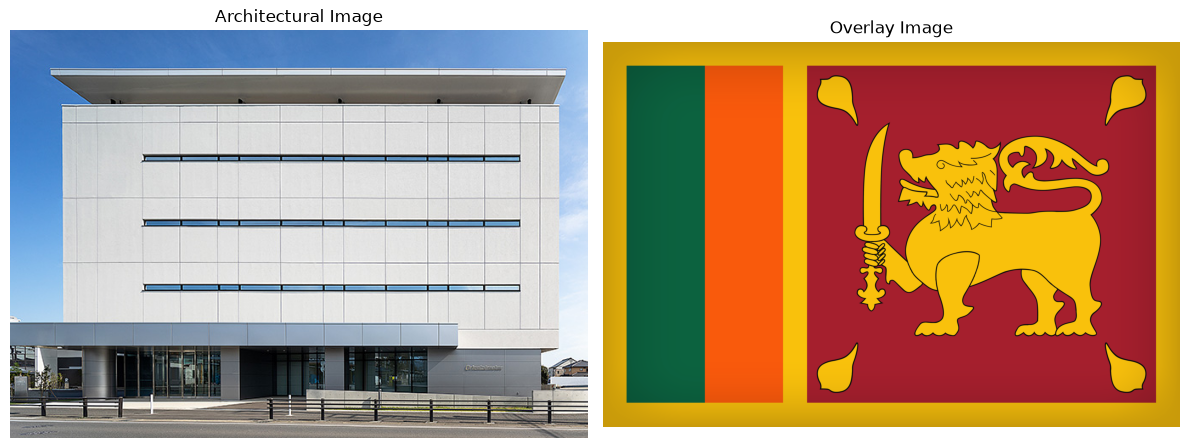

In [27]:
# Display both input images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(building, cv2.COLOR_BGR2RGB))
plt.title("Architectural Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Overlay Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
# Make a copy for displaying the selected points
display_image = building.copy()
selected_points = []

def choose_corners(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN and len(selected_points) < 4:
        selected_points.append([x, y])

        # Mark the selected corner
        cv2.circle(display_image, (x, y), 6, (0, 255, 0), -1)
        cv2.putText(
            display_image,
            str(len(selected_points)),
            (x + 8, y - 8),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 0, 255),
            2
        )

        cv2.imshow("Select four corners", display_image)
        print(f"Selected point {len(selected_points)}: ({x}, {y})")

# Open the image window
cv2.namedWindow("Select four corners")
cv2.imshow("Select four corners", display_image)
cv2.setMouseCallback("Select four corners", choose_corners)

print("Click the four surface corners in clockwise order.")
print("Press any key after selecting all four points.")

while len(selected_points) < 4:
    if cv2.waitKey(20) & 0xFF == 27:
        break

cv2.waitKey(0)
cv2.destroyAllWindows()

if len(selected_points) != 4:
    raise ValueError("Exactly four points must be selected.")

destination_points = np.array(selected_points, dtype=np.float32)

# Get the four corners of the overlay image
overlay_height, overlay_width = overlay.shape[:2]

source_points = np.array([
    [0, 0],
    [overlay_width - 1, 0],
    [overlay_width - 1, overlay_height - 1],
    [0, overlay_height - 1]
], dtype=np.float32)

# Compute the homography mapping overlay coordinates to the surface
H, status = cv2.findHomography(source_points, destination_points)

if H is None:
    raise RuntimeError("Homography estimation failed.")

print("Homography matrix:")
print(H)

Click the four surface corners in clockwise order.
Press any key after selecting all four points.
Selected point 1: (157, 156)
Selected point 2: (601, 156)
Selected point 3: (601, 302)
Selected point 4: (157, 302)
Homography matrix:
[[8.88177636e-02 0.00000000e+00 1.57000000e+02]
 [0.00000000e+00 4.38043804e-02 1.56000000e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


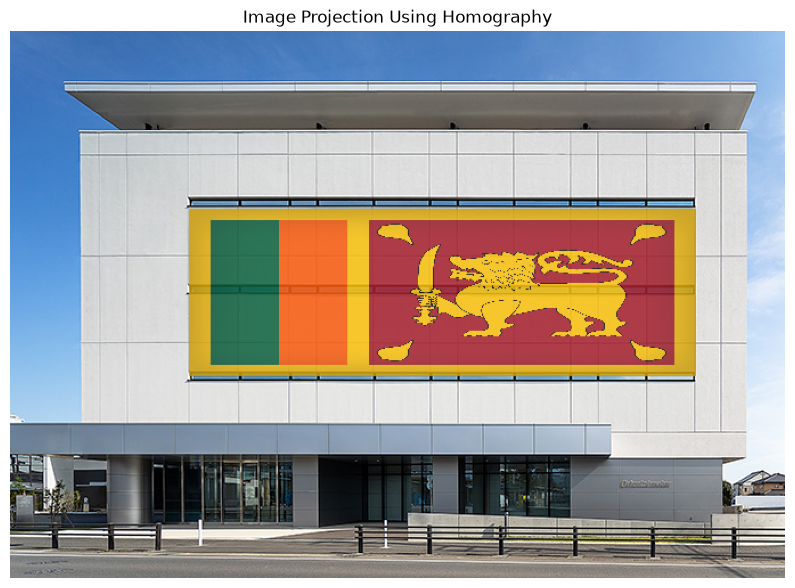

Result saved as: homography_result1.png


In [29]:
# Warp the overlay into the background image coordinates
height, width = building.shape[:2]

warped_overlay = cv2.warpPerspective(
    overlay,
    H,
    (width, height)
)

# Create a mask for the projected quadrilateral
surface_mask = np.zeros((height, width), dtype=np.uint8)

cv2.fillConvexPoly(
    surface_mask,
    destination_points.astype(np.int32),
    255
)

# Blend only within the selected surface
alpha = 0.85

result = building.copy()

region = surface_mask > 0

result[region] = cv2.addWeighted(
    building[region],
    1 - alpha,
    warped_overlay[region],
    alpha,
    0
)

# Display the final composite
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Image Projection Using Homography")
plt.axis("off")
plt.show()

# Save the result
output_path = "homography_result1.png"
cv2.imwrite(output_path, result)

print("Result saved as:", output_path)

Background image size: (4999, 4000, 3)
Overlay image size: (800, 800, 3)


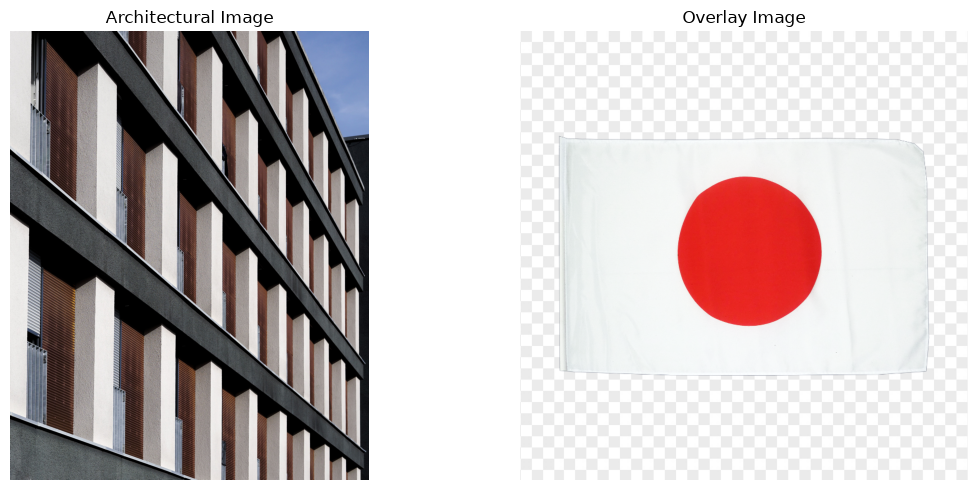

In [30]:


# Load the architectural image and the image to be projected
building_path = 'a2images/building2.jpg'
overlay_path = 'a2images/flag2.png'

building = cv2.imread(building_path)
overlay = cv2.imread(overlay_path)

if building is None or overlay is None:
    raise FileNotFoundError("Check the image paths and filenames.")

print("Background image size:", building.shape)
print("Overlay image size:", overlay.shape)

# Display both input images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(building, cv2.COLOR_BGR2RGB))
plt.title("Architectural Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title("Overlay Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
# Make a copy for displaying the selected points
display_image = building.copy()
selected_points = []

def choose_corners(event, x, y, flags, param):
    if event == cv2.EVENT_LBUTTONDOWN and len(selected_points) < 4:
        selected_points.append([x, y])

        # Mark the selected corner
        cv2.circle(display_image, (x, y), 6, (0, 255, 0), -1)
        cv2.putText(
            display_image,
            str(len(selected_points)),
            (x + 8, y - 8),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 0, 255),
            2
        )

        cv2.imshow("Select four corners", display_image)
        print(f"Selected point {len(selected_points)}: ({x}, {y})")

# Open the image window
cv2.namedWindow("Select four corners")
cv2.imshow("Select four corners", display_image)
cv2.setMouseCallback("Select four corners", choose_corners)

print("Click the four surface corners in clockwise order.")
print("Press any key after selecting all four points.")

while len(selected_points) < 4:
    if cv2.waitKey(20) & 0xFF == 27:
        break

cv2.waitKey(0)
cv2.destroyAllWindows()

if len(selected_points) != 4:
    raise ValueError("Exactly four points must be selected.")

destination_points = np.array(selected_points, dtype=np.float32)

# Get the four corners of the overlay image
overlay_height, overlay_width = overlay.shape[:2]

source_points = np.array([
    [0, 0],
    [overlay_width - 1, 0],
    [overlay_width - 1, overlay_height - 1],
    [0, overlay_height - 1]
], dtype=np.float32)

# Compute the homography mapping overlay coordinates to the surface
H, status = cv2.findHomography(source_points, destination_points)

if H is None:
    raise RuntimeError("Homography estimation failed.")

print("Homography matrix:")
print(H)

Click the four surface corners in clockwise order.
Press any key after selecting all four points.
Selected point 1: (2260, 187)
Selected point 2: (3510, 2274)
Selected point 3: (3514, 4291)
Selected point 4: (2249, 3215)
Homography matrix:
[[ 3.79795236e+00 -5.16691035e-02  2.26000000e+03]
 [ 4.05901551e+00  3.73555549e+00  1.87000000e+02]
 [ 6.36323873e-04 -1.68527765e-05  1.00000000e+00]]


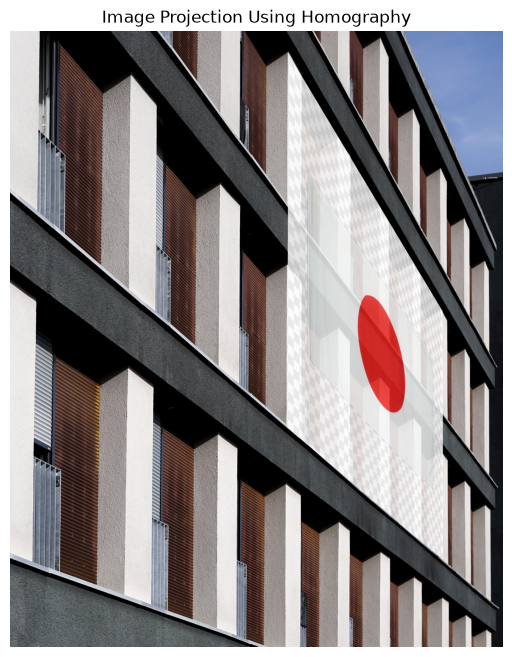

Result saved as: homography_result2.png


In [32]:
# Warp the overlay into the background image coordinates
height, width = building.shape[:2]

warped_overlay = cv2.warpPerspective(
    overlay,
    H,
    (width, height)
)

# Create a mask for the projected quadrilateral
surface_mask = np.zeros((height, width), dtype=np.uint8)

cv2.fillConvexPoly(
    surface_mask,
    destination_points.astype(np.int32),
    255
)

# Blend only within the selected surface
alpha = 0.85

result = building.copy()

region = surface_mask > 0

result[region] = cv2.addWeighted(
    building[region],
    1 - alpha,
    warped_overlay[region],
    alpha,
    0
)

# Display the final composite
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Image Projection Using Homography")
plt.axis("off")
plt.show()

# Save the result
output_path = "homography_result2.png"
cv2.imwrite(output_path, result)

print("Result saved as:", output_path)

## Discussion and Results

### Image Selection and Method

This experiment demonstrates homography-based image alignment by projecting the Sri Lankan flag onto a planar region of an architectural image. Four corner points were selected manually on the building facade, corresponding to the four corners of the flag image. These point correspondences were used to estimate a homography matrix that maps the flag coordinates to the selected region of the architectural image.

The estimated homography was used to perform perspective warping, adjusting the flag to the orientation and shape of the selected surface. The warped flag was then blended with the original architectural image. The same procedure was repeated using a second architectural image and the Japanese flag.

The Sri Lankan flag was selected for the first experiment because of its national significance, while the Japanese flag was used in the second experiment to demonstrate the method with a different image pair.

### Results and Observations

The homography successfully projects each flag onto the selected planar region of the corresponding architectural image. The perspective transformation accounts for differences in orientation and perspective between the original flag image and the building facade.

A mask restricts blending to the selected quadrilateral, leaving the surrounding architectural image unchanged. The blending parameter controls the relative contribution of the original building and the warped flag.

Both experiments demonstrate how a homography can be used for planar image alignment and realistic image placement. The accuracy of the projection depends on selecting the four corresponding corners correctly and ensuring that the selected surface is approximately planar.

## Question 4

Reference image: AECC1.jpg
Reference image dimensions: 2302 x 2730
Reference keypoints: 14274

Processing AAAA1.jpg...
Good matches: 51
RANSAC inliers: 18
Inlier ratio: 0.353
Saved results for AAAA1.jpg

Processing ADAD1.jpg...
Good matches: 370
RANSAC inliers: 195
Inlier ratio: 0.527
Saved results for ADAD1.jpg

Processing AECC2.jpg...
Good matches: 4321
RANSAC inliers: 3846
Inlier ratio: 0.89
Saved results for AECC2.jpg

Processing AECC3.jpg...
Good matches: 5629
RANSAC inliers: 5006
Inlier ratio: 0.889
Saved results for AECC3.jpg

Processing AECC4.jpg...
Good matches: 3830
RANSAC inliers: 3402
Inlier ratio: 0.888
Saved results for AECC4.jpg


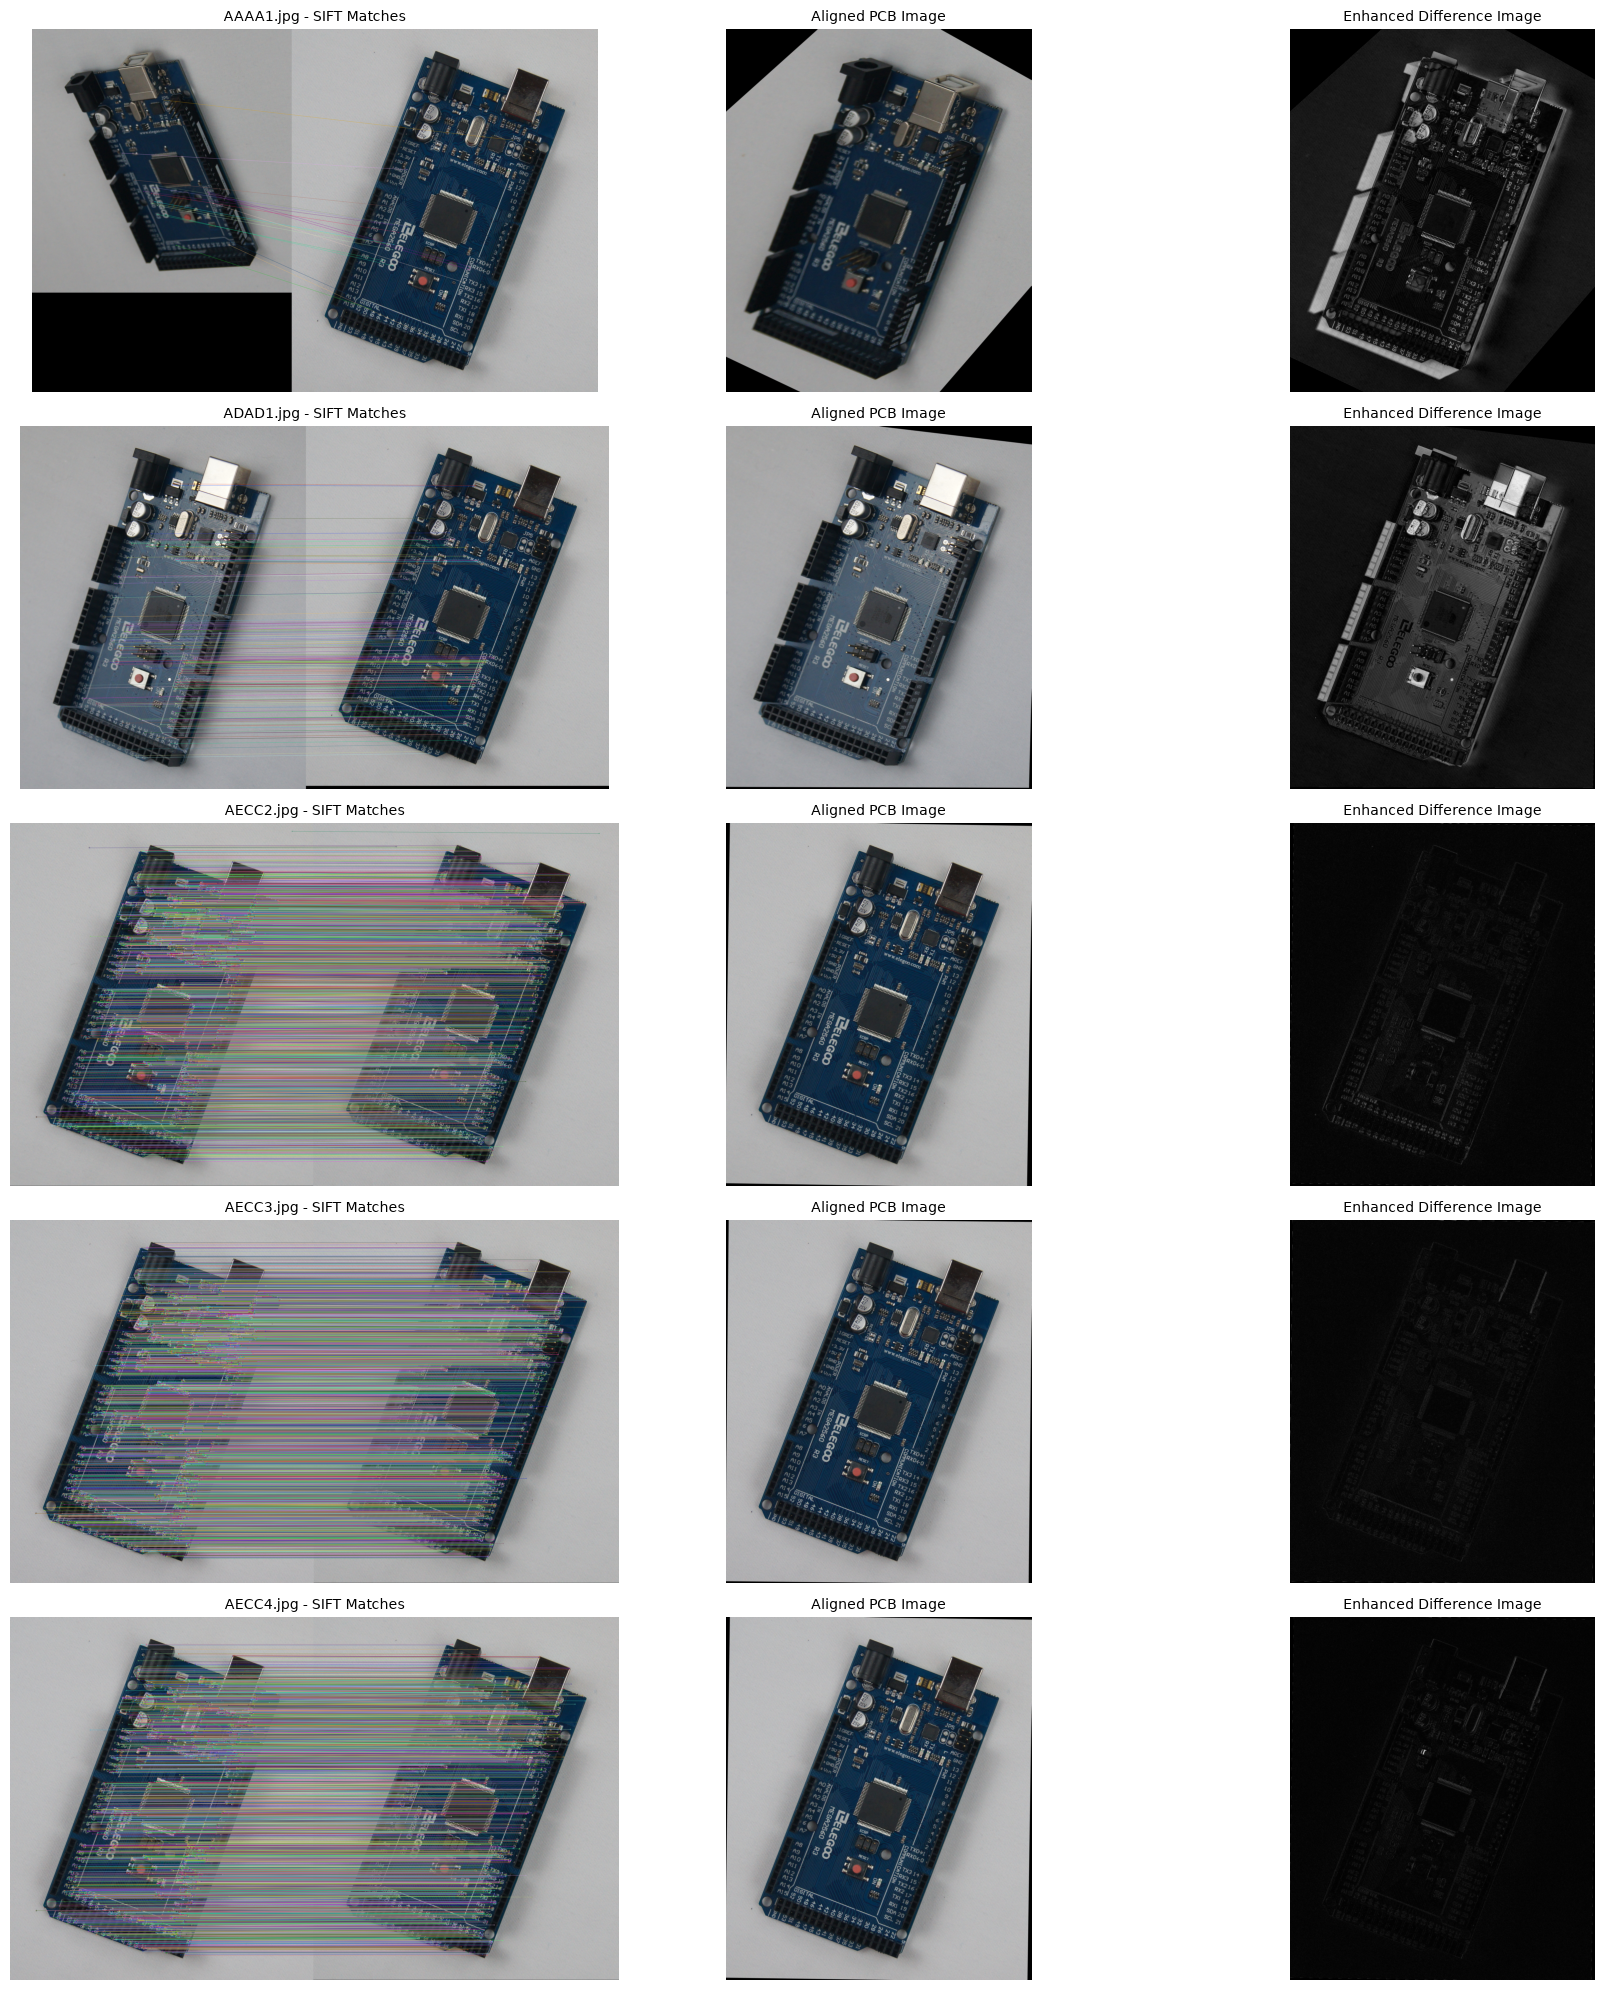


All PCB images processed.
Number of processed images: 5
Individual results: pcb_alignment_results
Combined figure: pcb_alignment_results/all_pcb_results.png


In [33]:
import os

template_path = 'a2images/AECC1.jpg'
template = cv2.imread(template_path)

if template is None:
    raise FileNotFoundError(
        f"Cannot load reference image: {template_path}"
    )

template_gray = cv2.cvtColor(template, cv2.COLOR_BGR2GRAY)
height, width = template.shape[:2]

print("Reference image: AECC1.jpg")
print("Reference image dimensions:", width, "x", height)

sift = cv2.SIFT_create()
template_keypoints, template_descriptors = sift.detectAndCompute(
    template_gray, None
)

if template_descriptors is None:
    raise RuntimeError("No SIFT features detected in AECC1.jpg.")

matcher = cv2.BFMatcher(cv2.NORM_L2)

print("Reference keypoints:", len(template_keypoints))

pcb_names = [
    'AAAA1.jpg',
    'ADAD1.jpg',
    'AECC2.jpg',
    'AECC3.jpg',
    'AECC4.jpg'
]

output_folder = 'pcb_alignment_results'
os.makedirs(output_folder, exist_ok=True)

all_results = []

for pcb_name in pcb_names:
    pcb_path = f'a2images/{pcb_name}'
    pcb = cv2.imread(pcb_path)

    if pcb is None:
        print(f"\nCannot load {pcb_name}. Skipping.")
        continue

    print(f"\nProcessing {pcb_name}...")

    pcb_gray = cv2.cvtColor(pcb, cv2.COLOR_BGR2GRAY)
    pcb_keypoints, pcb_descriptors = sift.detectAndCompute(
        pcb_gray, None
    )

    if pcb_descriptors is None or len(pcb_keypoints) < 4:
        print("Insufficient SIFT features. Skipping.")
        continue

    candidate_matches = matcher.knnMatch(
        pcb_descriptors,
        template_descriptors,
        k=2
    )

    # Retain matches that pass Lowe's ratio test.
    good_matches = [
        pair[0]
        for pair in candidate_matches
        if len(pair) == 2
        and pair[0].distance < 0.75 * pair[1].distance
    ]

    print("Good matches:", len(good_matches))

    if len(good_matches) < 4:
        print("Insufficient matches for homography.")
        continue

    pcb_points = np.float32([
        pcb_keypoints[m.queryIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    template_points = np.float32([
        template_keypoints[m.trainIdx].pt
        for m in good_matches
    ]).reshape(-1, 1, 2)

    # Estimate the homography using RANSAC.
    H, inlier_mask = cv2.findHomography(
        pcb_points,
        template_points,
        cv2.RANSAC,
        5.0
    )

    if H is None or inlier_mask is None:
        print("Homography estimation failed. Skipping.")
        continue

    inlier_count = int(inlier_mask.sum())
    inlier_ratio = float(inlier_mask.mean())

    print("RANSAC inliers:", inlier_count)
    print("Inlier ratio:", round(inlier_ratio, 3))

    match_image = cv2.drawMatches(
        pcb,
        pcb_keypoints,
        template,
        template_keypoints,
        good_matches,
        None,
        matchesMask=inlier_mask.ravel().tolist(),
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    # Warp the PCB image into the reference image coordinates.
    aligned_image = cv2.warpPerspective(
        pcb,
        H,
        (width, height)
    )

    # Warp a binary mask to identify valid pixels in the aligned image.
    source_mask = np.full(pcb.shape[:2], 255, dtype=np.uint8)

    aligned_mask = cv2.warpPerspective(
        source_mask,
        H,
        (width, height),
        flags=cv2.INTER_NEAREST
    )

    valid_region = aligned_mask > 0

    # Compute differences only in regions covered by the aligned PCB.
    difference_image = np.zeros_like(template)
    difference_image[valid_region] = cv2.absdiff(
        template[valid_region],
        aligned_image[valid_region]
    )

    gray_difference = cv2.cvtColor(
        difference_image,
        cv2.COLOR_BGR2GRAY
    )

    # Normalize the difference image to make variations easier to see.
    enhanced_difference = cv2.normalize(
        gray_difference,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    image_id = os.path.splitext(pcb_name)[0]

    cv2.imwrite(
        os.path.join(output_folder, f'{image_id}_matches.png'),
        match_image
    )

    cv2.imwrite(
        os.path.join(output_folder, f'{image_id}_aligned.png'),
        aligned_image
    )

    cv2.imwrite(
        os.path.join(output_folder, f'{image_id}_difference.png'),
        difference_image
    )

    cv2.imwrite(
        os.path.join(
            output_folder,
            f'{image_id}_difference_enhanced.png'
        ),
        enhanced_difference
    )

    all_results.append((
        pcb_name,
        match_image,
        aligned_image,
        enhanced_difference
    ))

    print("Saved results for", pcb_name)

if not all_results:
    raise RuntimeError("No PCB images were processed successfully.")

number_of_rows = len(all_results)

fig, axes = plt.subplots(
    number_of_rows,
    3,
    figsize=(18, 4 * number_of_rows),
    squeeze=False
)

for row, (pcb_name, match_img, aligned_img, diff_img) in enumerate(
    all_results
):
    axes[row, 0].imshow(
        cv2.cvtColor(match_img, cv2.COLOR_BGR2RGB)
    )
    axes[row, 0].set_title(
        f'{pcb_name} - SIFT Matches',
        fontsize=10
    )
    axes[row, 0].axis('off')

    axes[row, 1].imshow(
        cv2.cvtColor(aligned_img, cv2.COLOR_BGR2RGB)
    )
    axes[row, 1].set_title('Aligned PCB Image', fontsize=10)
    axes[row, 1].axis('off')

    axes[row, 2].imshow(
        diff_img,
        cmap='gray',
        vmin=0,
        vmax=255
    )
    axes[row, 2].set_title(
        'Enhanced Difference Image',
        fontsize=10
    )
    axes[row, 2].axis('off')

plt.tight_layout()

combined_path = os.path.join(
    output_folder,
    'all_pcb_results.png'
)

plt.savefig(
    combined_path,
    dpi=200,
    bbox_inches='tight'
)

plt.show()

print("\nAll PCB images processed.")
print("Number of processed images:", len(all_results))
print("Individual results:", output_folder)
print("Combined figure:", combined_path)

### (e) Discussion of High-Difference Regions

High differences around the USB Type-B port, capacitors, and reset button may result from small alignment errors, illumination changes, and reflections. These components have raised or reflective surfaces, making their appearance sensitive to camera angle and lighting conditions.

Although the homography corrects perspective differences, it cannot completely compensate for changes in illumination, shadows, or the three-dimensional structure of electronic components. Consequently, pixel differences may remain even after alignment. Therefore, high differences do not necessarily indicate defects; they may also result from imaging conditions and imperfect alignment.